In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install sklearn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
%pip install scikit-learn -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import pandas as pd
df = pd.read_csv("C:/Users/User/Downloads/Order_delivery.csv")
print(df)

        Order_ID User_ID  Restaurant_ID  Driver_ID      Item_Name  Quantity  \
0              1   U3522            358        485  Fried Chicken         3   
1              2   U9214            316         65       Sandwich         3   
2              3   U7307            357        309        Koshary         3   
3              4   U3612            420         32          Sushi         2   
4              5   U3492             73        364        Koshary         5   
...          ...     ...            ...        ...            ...       ...   
99997      99998   U2735             12         88  Fried Chicken         4   
99998      99999   U7356            570        473        Koshary         4   
99999     100000   U3960            790        283        Koshary         5   
100000    100001   U5821            345        172         Burger         2   
100001    100002   U9147            621        391          Pizza         3   

        Total_Price        Order_Time     Delivery_

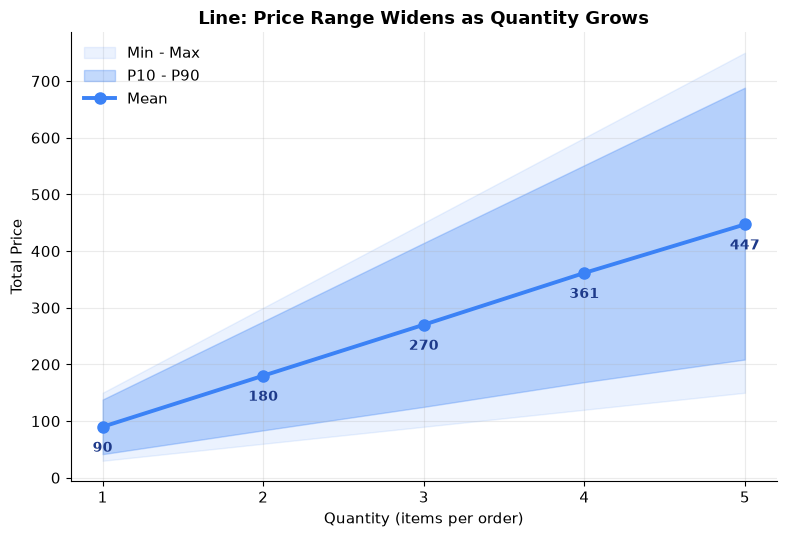

In [ ]:
#เมื่อสั่งอาหารจำนวนยชิ้นมากขึ้น(1-5ชิ้น)ราคาเฉลี่ยของออเดอร์
#เพิ่มขึ้นเป็นเท่าไหร่และกระจายตัวมากแค่ไหน

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- โหลดข้อมูล ----------
df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]

# ---------- สรุปข้อมูลตามจำนวนชิ้น ----------
g = data.groupby("qty")["price"]
summary = pd.DataFrame({
    "mean": g.mean(), "p10": g.quantile(0.10), "p90": g.quantile(0.90),
    "min": g.min(), "max": g.max(),
}).reset_index()

# ---------- ธีม ----------
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
BLUE = "#3b82f6"

# ---------- Line: ราคาเฉลี่ย + ช่วงราคาที่พบบ่อย (P10-P90) ----------
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.fill_between(summary["qty"], summary["min"], summary["max"], color=BLUE, alpha=0.10, label="Min - Max")
ax.fill_between(summary["qty"], summary["p10"], summary["p90"], color=BLUE, alpha=0.30, label="P10 - P90")
ax.plot(summary["qty"], summary["mean"], marker="o", markersize=8, color=BLUE, linewidth=2.8, label="Mean")
for q, m in zip(summary["qty"], summary["mean"]):
    ax.annotate(f"{m:.0f}", (q, m), textcoords="offset points", xytext=(0, -18),
                ha="center", fontsize=10, color="#1e3a8a", fontweight="bold")
ax.set_xticks(summary["qty"])
ax.set_title("Line: Price Range Widens as Quantity Grows")
ax.set_xlabel("Quantity (items per order)")
ax.set_ylabel("Total Price")
ax.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

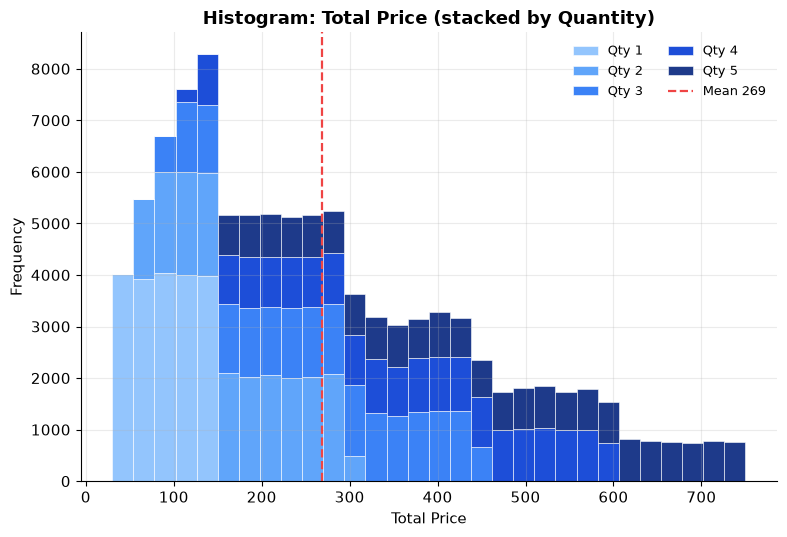

In [ ]:
#ราคารวมของออเดอร์เมื่อจำแนกตามระดับจำนวนสินค้าแต่ละกลุ่ม(1-5ชิ้น)
#มีรูปแบบการกระจายตัวอย่างไรและมีค่าเฉลี่ยแตกต่างกันอย่างไร

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- โหลดข้อมูล ----------
df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]

# ---------- ธีม ----------
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
RED = "#ef4444"
QCOLORS = ["#93c5fd", "#60a5fa", "#3b82f6", "#1d4ed8", "#1e3a8a"]   # สีของ Quantity 1-5

# ---------- Histogram: Total_Price แยกสีตาม Quantity (stacked) ----------
fig, ax = plt.subplots(figsize=(8, 5.5))
groups = [data.loc[data["qty"] == q, "price"] for q in range(1, 6)]
ax.hist(groups, bins=30, stacked=True, color=QCOLORS, edgecolor="white", linewidth=0.4,
        label=[f"Qty {q}" for q in range(1, 6)])
ax.axvline(data["price"].mean(), color=RED, linestyle="--", linewidth=1.6,
           label=f"Mean {data['price'].mean():.0f}")
ax.set_title("Histogram: Total Price (stacked by Quantity)")
ax.set_xlabel("Total Price")
ax.set_ylabel("Frequency")
ax.legend(frameon=False, ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

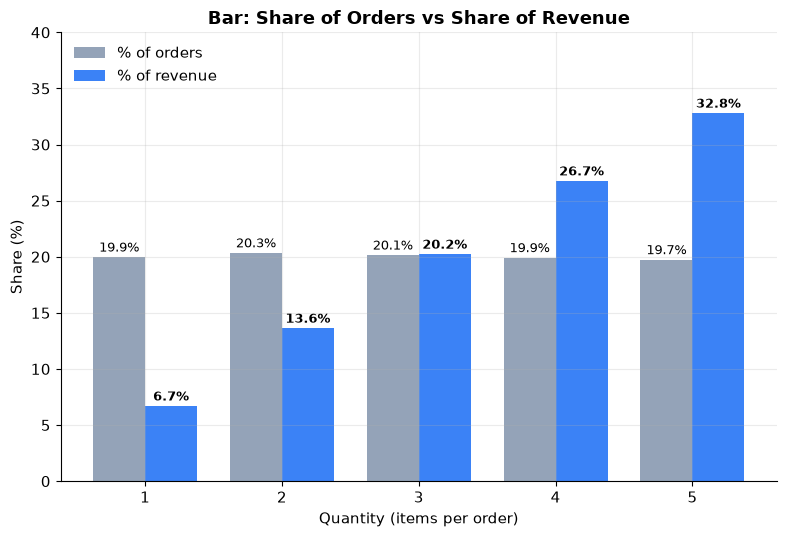

In [ ]:
#ลูกค้าสั่งออเดอร์แต่ละขนาดกี่เปอร์เซนต์และออเดอร์ขนาดกี่ชิ้นที่ทำรายได้รวมให้ร้านค้าได้มากที่สุด

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- โหลดข้อมูล ----------
df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]

# ---------- สรุปข้อมูลตามจำนวนชิ้น ----------
g = data.groupby("qty")["price"]
summary = pd.DataFrame({"orders": g.size(), "revenue": g.sum()}).reset_index()
summary["order_share"] = summary["orders"] / summary["orders"].sum() * 100
summary["revenue_share"] = summary["revenue"] / summary["revenue"].sum() * 100

# ---------- ธีม ----------
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
BLUE = "#3b82f6"

# ---------- Bar: สัดส่วนจำนวนออเดอร์ vs สัดส่วนรายได้ ----------
fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(summary))
w = 0.38
b1 = ax.bar(x - w / 2, summary["order_share"], w, color="#94a3b8", label="% of orders")
b2 = ax.bar(x + w / 2, summary["revenue_share"], w, color=BLUE, label="% of revenue")
ax.bar_label(b1, fmt="%.1f%%", fontsize=9, padding=2)
ax.bar_label(b2, fmt="%.1f%%", fontsize=9, padding=2, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(summary["qty"])
ax.set_ylim(0, 40)
ax.set_title("Bar: Share of Orders vs Share of Revenue")
ax.set_xlabel("Quantity (items per order)")
ax.set_ylabel("Share (%)")
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
from pathlib import Path

df = pd.read_csv(r"C:/Users/MYASUS/Downloads/Order_delivery.csv")
TAB = Path("tables")
TAB.mkdir(exist_ok=True)

In [14]:
import pandas as pd
from pathlib import Path

df = pd.read_csv(r"C:/Users/MYASUS/Downloads/Order_delivery.csv")
TAB = Path("tables")
TAB.mkdir(exist_ok=True)

print(type(df)) 
df.head()

<class 'pandas.DataFrame'>


,Order_ID,User_ID,Restaurant_ID,Driver_ID,Item_Name,Quantity,Total_Price,Order_Time,Delivery_Time,Delivery_Duration_Minutes,...,Driver_Vehicle,Restaurant_Lat,Restaurant_Lon,Customer_Lat,Customer_Lon,Driver_Lat,Driver_Lon,Delivery_Distance_km,Traffic_Level,Driver_Availability
0,1,U3522,358,485,Fried Chicken,3,273.72,16-06-2025 08:32,16-06-2025 09:11,39,...,Motorbike,31.195082,29.921931,31.191404,29.904982,31.215658,29.910664,1.666106,High,Offline
1,2,U9214,316,65,Sandwich,3,365.82,03-06-2025 21:27,03-06-2025 22:00,33,...,Motorbike,30.605729,31.503079,30.586047,31.485820,30.580329,31.502380,2.738698,Low,Online
2,3,U7307,357,309,Koshary,3,401.94,01-06-2025 14:48,01-06-2025 15:26,38,...,Car,27.190180,31.177741,27.164869,31.169218,27.162976,31.189458,2.929079,Medium,Online
3,4,U3612,420,32,Sushi,2,221.18,13-06-2025 02:30,13-06-2025 03:22,52,...,Car,31.041846,31.381229,31.035773,31.380440,31.054690,31.401187,0.677498,Low,Online
4,5,U3492,73,364,Koshary,5,355.55,06-06-2025 09:48,06-06-2025 10:32,44,...,Motorbike,31.024141,31.376104,31.026023,31.396881,31.035350,31.389315,1.994769,High,Online


In [1]:
import pandas as pd

CSV_PATH = r"C:/Users/MYASUS/Desktop/Data/Order_delivery1.csv"

df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]
data = data[data["qty"].between(1, 5)]
g = data.groupby("qty")["price"]

pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ======================= ข้อ 1 =======================
q1 = pd.DataFrame({
    "จำนวนออเดอร์": g.size(),
    "ราคาเฉลี่ย": g.mean(),
    "ราคาต่ำสุด": g.min(),
    "ราคาสูงสุด": g.max(),
    "ช่วงราคา(max-min)": g.max() - g.min(),
    "P10": g.quantile(0.10),
    "P90": g.quantile(0.90),
    "SD": g.std(),
})
q1["เพิ่มจากกลุ่มก่อนหน้า(บาท)"] = q1["ราคาเฉลี่ย"].diff()
q1["เพิ่มจากกลุ่มก่อนหน้า(%)"] = q1["ราคาเฉลี่ย"].pct_change() * 100
print("=" * 30, "ข้อ 1: ราคาเฉลี่ยและการกระจายตัวตามจำนวนชิ้น", "=" * 30)
print(q1.to_string())
print(f"\nจาก 1 ชิ้น -> 5 ชิ้น ราคาเฉลี่ยเพิ่มจาก {q1.loc[1,'ราคาเฉลี่ย']:,.2f} เป็น {q1.loc[5,'ราคาเฉลี่ย']:,.2f} บาท "
      f"(เพิ่ม {q1.loc[5,'ราคาเฉลี่ย']-q1.loc[1,'ราคาเฉลี่ย']:,.2f} บาท, เฉลี่ยชิ้นละ {q1['เพิ่มจากกลุ่มก่อนหน้า(บาท)'].mean():,.2f} บาท)")

# ======================= ข้อ 2 =======================
q2 = g.describe(percentiles=[0.25, 0.5, 0.75])[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
q2["IQR"] = q2["75%"] - q2["25%"]
q2["CV(%)"] = q2["std"] / q2["mean"] * 100
q2["skew"] = g.skew()
print("\n" + "=" * 30, "ข้อ 2: รูปแบบการกระจายตัวของราคารวมแต่ละกลุ่ม", "=" * 30)
print(q2.to_string())
print(f"\nค่าเฉลี่ยรวมทุกออเดอร์ (1-5 ชิ้น): {data['price'].mean():,.2f} บาท | มัธยฐานรวม: {data['price'].median():,.2f} บาท")
print("ส่วนต่างค่าเฉลี่ยแต่ละกลุ่มเทียบค่าเฉลี่ยรวม:")
print((q2["mean"] - data["price"].mean()).to_string())

# ======================= ข้อ 3 =======================
q3 = pd.DataFrame({"จำนวนออเดอร์": g.size(), "รายได้รวม": g.sum()})
q3["สัดส่วนออเดอร์(%)"] = q3["จำนวนออเดอร์"] / q3["จำนวนออเดอร์"].sum() * 100
q3["สัดส่วนรายได้(%)"] = q3["รายได้รวม"] / q3["รายได้รวม"].sum() * 100
print("\n" + "=" * 30, "ข้อ 3: สัดส่วนออเดอร์และรายได้", "=" * 30)
print(q3.to_string())
top = q3["รายได้รวม"].idxmax()
print(f"\nขนาดที่สั่งมากที่สุด: {q3['สัดส่วนออเดอร์(%)'].idxmax()} ชิ้น ({q3['สัดส่วนออเดอร์(%)'].max():.2f}%)")
print(f"ขนาดที่ทำรายได้รวมสูงสุด: {top} ชิ้น ({q3.loc[top,'รายได้รวม']:,.2f} บาท = {q3.loc[top,'สัดส่วนรายได้(%)']:.2f}% ของรายได้ทั้งหมด)")

============================== ข้อ 1: ราคาเฉลี่ยและการกระจายตัวตามจำนวนชิ้น ==============================
     จำนวนออเดอร์  ราคาเฉลี่ย  ราคาต่ำสุด  ราคาสูงสุด  ช่วงราคา(max-min)    P10    P90     SD  เพิ่มจากกลุ่มก่อนหน้า(บาท)  เพิ่มจากกลุ่มก่อนหน้า(%)
qty                                                                                                                                                
1           19945       89.98       30.00      149.99             119.99  41.70 138.07  34.72                         NaN                       NaN
2           20323      180.08       60.00      300.00             240.00  83.68 275.92  69.30                       90.10                    100.13
3           20125      270.02       90.00      449.91             359.91 125.11 414.33 104.17                       89.94                     49.94
4           19895      361.41      120.00      599.96             479.96 168.72 551.48 138.21                       91.39                     33.84
5    

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------------------------------------
# 0. ตั้งค่า path และโหลดข้อมูล
# -------------------------------------------------------------------------
# โฟลเดอร์หลักของโครงงาน
ROOT = Path(r"C:/Users/MYASUS/Downloads/Python")

# กำหนดที่อยู่ไฟล์ CSV
# ถ้าค้นหาไม่เจอ ให้ใส่ path เต็มของไฟล์ที่นี่ เช่น
# DATA_MANUAL = Path(r"C:/Users/MYASUS/Desktop/Order_delivery1.csv")
DATA_MANUAL = Path(r"C:/Users/MYASUS/Desktop/Data/Order_delivery1.csv")

HOME = Path.home()
SEARCH_DIRS = [
    ROOT, Path.cwd(),
    HOME / "Downloads", HOME / "Desktop", HOME / "Documents",
    HOME / "OneDrive", HOME / "OneDrive" / "Desktop", HOME / "OneDrive" / "Documents",
]
SEARCH_DIRS = [d for d in SEARCH_DIRS if d.exists()]

DATA = DATA_MANUAL
if DATA is None:
    # 1) ค้นในโฟลเดอร์ตรง ๆ ก่อน  2) ถ้ายังไม่เจอ ค้นลึกลงไปในโฟลเดอร์ย่อยด้วย
    for pattern_fn in (lambda d: d.glob("Order_delivery1*.csv"),
                       lambda d: d.rglob("Order_delivery1*.csv")):
        for folder in SEARCH_DIRS:
            found = sorted(pattern_fn(folder))
            if found:
                DATA = found[0]
                break
        if DATA is not None:
            break

if DATA is None:
    raise FileNotFoundError(
        "ไม่พบไฟล์ Order_delivery1.csv ในโฟลเดอร์ที่ค้นหา (รวมโฟลเดอร์ย่อย) -> "
        + ", ".join(str(d) for d in SEARCH_DIRS)
        + "\nให้ใส่ path เต็มของไฟล์ใน DATA_MANUAL"
    )
print("ใช้ไฟล์ข้อมูล:", DATA)

RESULT = Path(r"C:/Users/MYASUS/Desktop/result")
TAB = RESULT / "Table"
FIG = RESULT / "Figure"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# โหลดข้อมูลจากไฟล์ CSV
df = pd.read_csv(DATA)
print(f"โหลดข้อมูล {len(df)} แถว {df.shape[1]} คอลัมน์")
print(f"ราคารวมต่ำสุด-สูงสุด: {df['Total_Price'].min():,.0f} - {df['Total_Price'].max():,.0f}")

# -------------------------------------------------------------------------
# จัดกลุ่มข้อมูลและกำหนดลำดับตัวแปร
# -------------------------------------------------------------------------
# จัดกลุ่มเมือง (City)
TOP_CITIES = ["Zagazig", "Cairo", "Tanta", "Assiut", "Giza", "Alexandria", "Mansoura"]
df["city_group"] = df["City"].where(df["City"].isin(TOP_CITIES), "Other")

# เรียงลำดับหมวดหมู่ให้อ่านง่าย
ORDER_VEHICLE = ["Bicycle", "Motorbike", "Car"]
ORDER_AVAILABILITY = ["Offline", "Online"]
ORDER_CITY = ["Zagazig", "Cairo", "Tanta", "Assiut", "Giza", "Alexandria", "Mansoura"]

# จัดรูปแบบข้อความในคอลัมน์ให้อยู่ในรูปแบบมาตรฐาน (ตัดช่องว่าง/ไม่สนตัวพิมพ์เล็ก-ใหญ่)
key = df["City"].str.strip().str.lower()
canon = df.groupby(key)["City"].agg(lambda s: s.value_counts().index[0])
df["city_std"] = key.map(canon)

# ตั้งค่าธีมและสไตล์ของ กราฟ Matplotlib
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3
})

BLUE, ORANGE = "#2f6db5", "#e07b39"

def save(name):
    """บันทึกกราฟลง results/figures แล้วแสดงในโน้ตบุ๊ก"""
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150)
    plt.show()
    print("บันทึกกราฟ:", name)

ใช้ไฟล์ข้อมูล: C:\Users\MYASUS\Desktop\Data\Order_delivery1.csv
โหลดข้อมูล 100002 แถว 23 คอลัมน์
ราคารวมต่ำสุด-สูงสุด: 30 - 750


In [9]:
from pathlib import Path

import numpy as np
import pandas as pd

# -------------------------------------------------------------------------
# 0. ตั้งค่า path และโหลดข้อมูล
# -------------------------------------------------------------------------
# โฟลเดอร์หลักของโครงงาน
ROOT = Path(r"C:/Users/MYASUS/Desktop/result")

# โฟลเดอร์ Table (ไฟล์ข้อมูลอยู่ที่นี่ และตารางคำตอบจะถูกบันทึกที่นี่ด้วย)
TAB = ROOT / "Table"
TAB.mkdir(parents=True, exist_ok=True)

DATA = TAB / "Order_delivery1.csv"
if not DATA.exists():
    raise FileNotFoundError(f"ไม่พบไฟล์ข้อมูล: {DATA}\nให้นำ Order_delivery1.csv ไปวางในโฟลเดอร์ Table แล้วรันใหม่")

# ตัวเลือก: ตั้งเป็น True ถ้าต้องการตัดออเดอร์ที่ถูกยกเลิก (Cancelled) ออกก่อนคำนวณ
EXCLUDE_CANCELLED = False

df = pd.read_csv(DATA)
if EXCLUDE_CANCELLED:
    df = df[df["Order_Status"] != "Cancelled"]

print(f"โหลดข้อมูล {len(df):,} แถว {df.shape[1]} คอลัมน์")
print(f"ราคารวมต่ำสุด-สูงสุด: {df['Total_Price'].min():,.2f} - {df['Total_Price'].max():,.2f}")

# ตัวแปรที่ใช้วิเคราะห์: ขนาดออเดอร์ = จำนวนชิ้น (Quantity 1-5), ราคา = Total_Price
df = df[df["Quantity"].between(1, 5)]
g = df.groupby("Quantity")["Total_Price"]
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 250
pd.options.display.max_columns = None


def save_table(table, name):
    table.to_csv(TAB / name, encoding="utf-8-sig")


# -------------------------------------------------------------------------
# ข้อ 1. ราคาเฉลี่ยของออเดอร์เมื่อจำนวนชิ้นเพิ่มขึ้น และการกระจายตัว (ค่าเฉลี่ย + ช่วงราคา)
# -------------------------------------------------------------------------
q1 = pd.DataFrame({
    "จำนวนออเดอร์": g.count(),
    "ราคาเฉลี่ย": g.mean(),
    "ราคาต่ำสุด": g.min(),
    "ราคาสูงสุด": g.max(),
})
q1["ช่วงราคา(สูงสุด-ต่ำสุด)"] = q1["ราคาสูงสุด"] - q1["ราคาต่ำสุด"]
q1["ส่วนเบี่ยงเบนมาตรฐาน"] = g.std()
q1["ราคาเฉลี่ยเพิ่มจากกลุ่มก่อนหน้า"] = q1["ราคาเฉลี่ย"].diff()
q1["เพิ่มขึ้น(%)"] = q1["ราคาเฉลี่ย"].pct_change() * 100

print("\n" + "=" * 80)
print("ข้อ 1: ราคาเฉลี่ยและการกระจายตัวของออเดอร์ แยกตามจำนวนชิ้น")
print("=" * 80)
print(q1)
print(f"\nจาก 1 ชิ้น เป็น 5 ชิ้น ราคาเฉลี่ยเพิ่มจาก {q1.loc[1, 'ราคาเฉลี่ย']:,.2f} "
      f"เป็น {q1.loc[5, 'ราคาเฉลี่ย']:,.2f} (เพิ่มขึ้น {q1.loc[5, 'ราคาเฉลี่ย'] - q1.loc[1, 'ราคาเฉลี่ย']:,.2f} "
      f"หรือ {q1.loc[5, 'ราคาเฉลี่ย'] / q1.loc[1, 'ราคาเฉลี่ย']:.2f} เท่า)")
save_table(q1, "q1_avg_price_by_quantity.csv")

# -------------------------------------------------------------------------
# ข้อ 2. รูปแบบการกระจายตัวของราคารวมในแต่ละกลุ่มจำนวนชิ้น และค่าเฉลี่ยที่แตกต่างกัน
# -------------------------------------------------------------------------
q2 = g.describe(percentiles=[0.25, 0.5, 0.75]).drop(columns="count")
q2.columns = ["ค่าเฉลี่ย", "ส่วนเบี่ยงเบนมาตรฐาน", "ต่ำสุด", "Q1(25%)", "มัธยฐาน", "Q3(75%)", "สูงสุด"]
q2["IQR(Q3-Q1)"] = q2["Q3(75%)"] - q2["Q1(25%)"]
q2["สัมประสิทธิ์การแปรผัน(CV,%)"] = q2["ส่วนเบี่ยงเบนมาตรฐาน"] / q2["ค่าเฉลี่ย"] * 100
q2["ความเบ้(skew)"] = g.skew()
overall_mean = df["Total_Price"].mean()
q2["ต่างจากค่าเฉลี่ยรวม"] = q2["ค่าเฉลี่ย"] - overall_mean

print("\n" + "=" * 80)
print("ข้อ 2: การกระจายตัวของราคารวม แยกตามจำนวนชิ้น")
print("=" * 80)
print(q2)
print(f"\nค่าเฉลี่ยรวมทุกออเดอร์ (ทุกกลุ่ม): {overall_mean:,.2f}")
save_table(q2, "q2_price_distribution_by_quantity.csv")

# -------------------------------------------------------------------------
# ข้อ 3. สัดส่วนออเดอร์ (%) และสัดส่วนรายได้ (%) ของแต่ละขนาดออเดอร์
# -------------------------------------------------------------------------
q3 = pd.DataFrame({
    "จำนวนออเดอร์": g.count(),
    "รายได้รวม": g.sum(),
})
q3["สัดส่วนออเดอร์(%)"] = q3["จำนวนออเดอร์"] / q3["จำนวนออเดอร์"].sum() * 100
q3["สัดส่วนรายได้(%)"] = q3["รายได้รวม"] / q3["รายได้รวม"].sum() * 100
q3["ส่วนต่างสัดส่วนรายได้-ออเดอร์(จุด%)"] = q3["สัดส่วนรายได้(%)"] - q3["สัดส่วนออเดอร์(%)"]

print("\n" + "=" * 80)
print("ข้อ 3: สัดส่วนออเดอร์และรายได้ แยกตามจำนวนชิ้น")
print("=" * 80)
print(q3)
top = q3["รายได้รวม"].idxmax()
print(f"\nออเดอร์ขนาด {top} ชิ้น ทำรายได้รวมสูงสุด {q3.loc[top, 'รายได้รวม']:,.2f} "
      f"({q3.loc[top, 'สัดส่วนรายได้(%)']:.2f}% ของรายได้ทั้งหมด)")
print(f"ขนาดออเดอร์ที่ลูกค้าสั่งมากที่สุด: {q3['จำนวนออเดอร์'].idxmax()} ชิ้น "
      f"({q3['สัดส่วนออเดอร์(%)'].max():.2f}% ของออเดอร์ทั้งหมด)")
save_table(q3, "q3_order_and_revenue_share.csv")

print(f"\nบันทึกตารางคำตอบลงโฟลเดอร์: {TAB}")

โหลดข้อมูล 100,002 แถว 23 คอลัมน์
ราคารวมต่ำสุด-สูงสุด: 30.00 - 750.00

ข้อ 1: ราคาเฉลี่ยและการกระจายตัวของออเดอร์ แยกตามจำนวนชิ้น
          จำนวนออเดอร์  ราคาเฉลี่ย  ราคาต่ำสุด  ราคาสูงสุด  ช่วงราคา(สูงสุด-ต่ำสุด)  ส่วนเบี่ยงเบนมาตรฐาน  ราคาเฉลี่ยเพิ่มจากกลุ่มก่อนหน้า  เพิ่มขึ้น(%)
Quantity                                                                                                                                                
1                19945       89.98       30.00      149.99                   119.99                 34.72                              NaN           NaN
2                20323      180.08       60.00      300.00                   240.00                 69.30                            90.10        100.13
3                20125      270.02       90.00      449.91                   359.91                104.17                            89.94         49.94
4                19895      361.41      120.00      599.96                   479.96                138.2

Linear Regression : R2 train = 0.5486 | R2 test = 0.5490
  สมการ: Quantity = 0.00613 * Total_Price + 1.3429

 degree  R2_train  R2_test     gap
      1    0.5486   0.5490 -0.0005
      2    0.5912   0.5909  0.0003
      3    0.5431   0.5427  0.0004
      4    0.4750   0.4749  0.0001


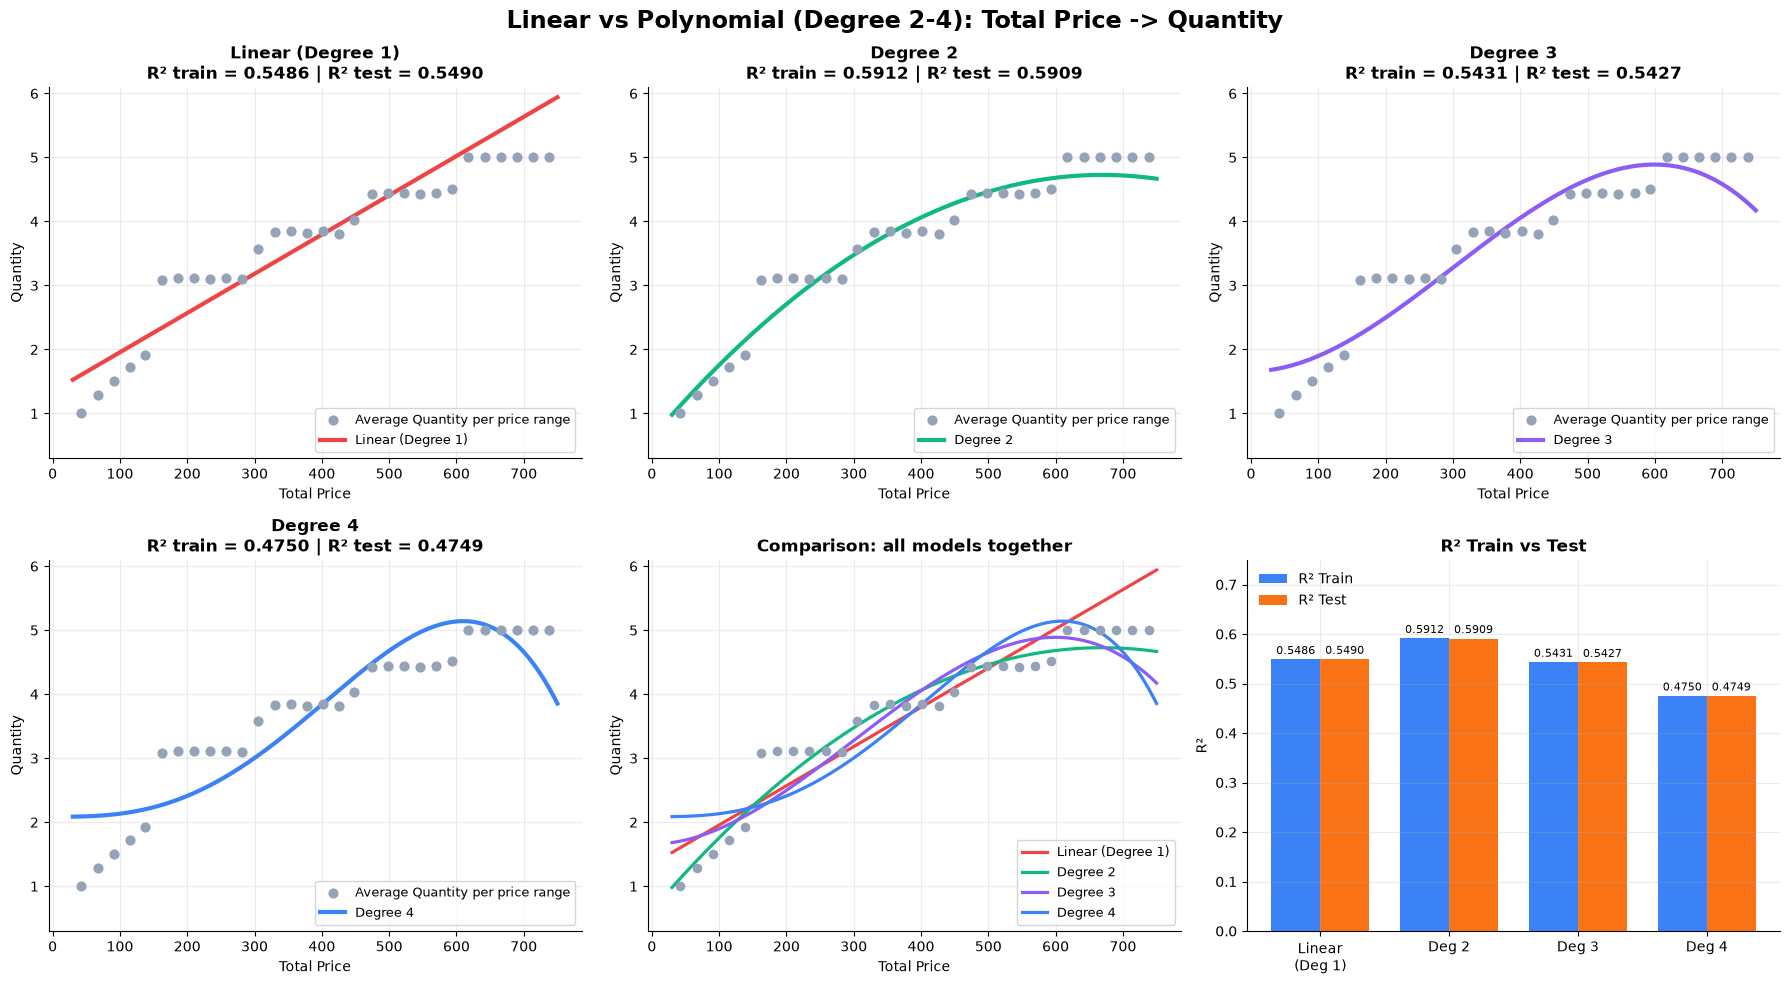

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score

CSV_PATH = CSV_PATH = r"C:/Users/MYASUS/Desktop/Data/Order_delivery1.csv"

# ---------- 1) โหลดข้อมูล + เลือกตัวแปร ----------
df = pd.read_csv(CSV_PATH)
X = df[["Total_Price"]]   # ตัวแปรต้น  (ราคารวมของออเดอร์)
y = df["Quantity"]        # ตัวแปรตาม (จำนวนชิ้น)

# ---------- 2) แบ่ง train / test (80 / 20) ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------- 3) Linear Regression (เส้นตรง) ----------
linear = LinearRegression().fit(X_train, y_train)
lin_train = r2_score(y_train, linear.predict(X_train))
lin_test = r2_score(y_test, linear.predict(X_test))
print(f"Linear Regression : R2 train = {lin_train:.4f} | R2 test = {lin_test:.4f}")
print(f"  สมการ: Quantity = {linear.coef_[0]:.5f} * Total_Price + {linear.intercept_:.4f}\n")

# ---------- 4) Polynomial degree 1, 2, 3, 4 ----------
degrees = [1, 2, 3, 4]
rows, models = [], {}
for d in degrees:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    model.fit(X_train, y_train)
    rows.append({
        "degree": d,
        "R2_train": r2_score(y_train, model.predict(X_train)),
        "R2_test": r2_score(y_test, model.predict(X_test)),
    })
    models[d] = model

res = pd.DataFrame(rows)
res["gap"] = res["R2_train"] - res["R2_test"]
print(res.round(4).to_string(index=False))

# ---------- 5) วาดกราฟ ----------
bins = pd.cut(df["Total_Price"], bins=30)
binned = df.groupby(bins, observed=True).agg(price=("Total_Price", "mean"),
                                              qty=("Quantity", "mean"))
xs = pd.DataFrame({"Total_Price": np.linspace(30, 750, 300)})
colors = {1: "#ef4444", 2: "#10b981", 3: "#8b5cf6", 4: "#3b82f6"}
names = {1: "Linear (Degree 1)", 2: "Degree 2", 3: "Degree 3", 4: "Degree 4"}

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Linear vs Polynomial (Degree 2-4): Total Price -> Quantity",
             fontsize=17, fontweight="bold")

# 5.1 กราฟแยก: 1 กราฟ = 1 เส้น (Linear, Degree 2, 3, 4)
for ax, d in zip([axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 0]], degrees):
    r = res.loc[d - 1]
    ax.scatter(binned["price"], binned["qty"], s=40, color="#94a3b8", zorder=3,
               label="Average Quantity per price range")
    ax.plot(xs["Total_Price"], models[d].predict(xs), linewidth=3, color=colors[d], label=names[d])
    ax.set_title(f"{names[d]}\nR² train = {r['R2_train']:.4f} | R² test = {r['R2_test']:.4f}")
    ax.set_xlabel("Total Price")
    ax.set_ylabel("Quantity")
    ax.set_ylim(0.3, 6.1)
    ax.legend(loc="lower right", frameon=True, fontsize=9)

# 5.2 กราฟเทียบทุกเส้นรวมกัน
ax = axes[1, 1]
ax.scatter(binned["price"], binned["qty"], s=35, color="#94a3b8", zorder=3)
for d in degrees:
    ax.plot(xs["Total_Price"], models[d].predict(xs), linewidth=2.3, color=colors[d], label=names[d])
ax.set_title("Comparison: all models together")
ax.set_xlabel("Total Price")
ax.set_ylabel("Quantity")
ax.set_ylim(0.3, 6.1)
ax.legend(loc="lower right", frameon=True, fontsize=9)

# 5.3 กราฟเทียบ R² train vs test
ax = axes[1, 2]
x = np.arange(len(degrees)); w = 0.38
b1 = ax.bar(x - w / 2, res["R2_train"], w, color="#3b82f6", label="R² Train")
b2 = ax.bar(x + w / 2, res["R2_test"], w, color="#f97316", label="R² Test")
ax.bar_label(b1, fmt="%.4f", fontsize=8, padding=2)
ax.bar_label(b2, fmt="%.4f", fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(["Linear\n(Deg 1)", "Deg 2", "Deg 3", "Deg 4"])
ax.set_ylim(0, 0.75)
ax.set_title("R² Train vs Test")
ax.set_ylabel("R²")
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

In [3]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score

# ที่อยู่ไฟล์ข้อมูล (อยู่ในโฟลเดอร์ Table)
CSV_PATH = Path(r"C:/Users/MYASUS/Desktop/Data/Order_delivery1.csv")   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- 1) โหลดข้อมูล + เลือกตัวแปร ----------
df = pd.read_csv(CSV_PATH)
X = df[["Total_Price"]]   # ตัวแปรต้น  (ราคารวมของออเดอร์)
y = df["Quantity"]        # ตัวแปรตาม (จำนวนชิ้น)

# ---------- 2) แบ่ง train / test (80 / 20) ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------- 3) Linear Regression (เส้นตรง) ----------
linear = LinearRegression().fit(X_train, y_train)
lin_train = r2_score(y_train, linear.predict(X_train))
lin_test = r2_score(y_test, linear.predict(X_test))
print(f"Linear Regression : R2 train = {lin_train:.4f} | R2 test = {lin_test:.4f}")
print(f"  สมการ: Quantity = {linear.coef_[0]:.5f} * Total_Price + {linear.intercept_:.4f}\n")

# ---------- 4) Polynomial degree 1, 2, 3, 4 ----------
degrees = [1, 2, 3, 4]
rows = []
for d in degrees:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    model.fit(X_train, y_train)
    rows.append({
        "degree": d,
        "R2_train": r2_score(y_train, model.predict(X_train)),
        "R2_test": r2_score(y_test, model.predict(X_test)),
    })

res = pd.DataFrame(rows)
res["gap"] = res["R2_train"] - res["R2_test"]
print(res.round(4).to_string(index=False))

Linear Regression : R2 train = 0.5486 | R2 test = 0.5490
  สมการ: Quantity = 0.00613 * Total_Price + 1.3429

 degree  R2_train  R2_test     gap
      1    0.5486   0.5490 -0.0005
      2    0.5912   0.5909  0.0003
      3    0.5431   0.5427  0.0004
      4    0.4750   0.4749  0.0001


In [4]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score

# --------------------------------------------------
# 0) กำหนด Path สำหรับอ่านข้อมูลและบันทึกผลลัพธ์
# --------------------------------------------------
CSV_PATH = Path(r"C:\Users\MYASUS\Desktop\Data\Order_delivery1.csv")

# โฟลเดอร์ปลายทางสำหรับบันทึกผลลัพธ์
OUTPUT_DIR = Path(r"C:\Users\MYASUS\Desktop\result\Table")
# สร้างโฟลเดอร์อัตโนมัติหากยังไม่มีอยู่
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1) โหลดข้อมูล + เลือกตัวแปร
# --------------------------------------------------
df = pd.read_csv(CSV_PATH)
X = df[["Total_Price"]]   # ตัวแปรต้น  (ราคารวมของออเดอร์)
y = df["Quantity"]        # ตัวแปรตาม (จำนวนชิ้น)

# --------------------------------------------------
# 2) แบ่ง train / test (80 / 20)
# --------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --------------------------------------------------
# 3) Linear Regression (เส้นตรง)
# --------------------------------------------------
linear = LinearRegression().fit(X_train, y_train)
lin_train = r2_score(y_train, linear.predict(X_train))
lin_test = r2_score(y_test, linear.predict(X_test))

coef = linear.coef_[0]
intercept = linear.intercept_

print(f"Linear Regression : R2 train = {lin_train:.4f} | R2 test = {lin_test:.4f}")
print(f"  สมการ: Quantity = {coef:.5f}*Total_Price + {intercept:.4f}\n")

# --------------------------------------------------
# 4) Polynomial degree 1, 2, 3, 4
# --------------------------------------------------
degrees = [1, 2, 3, 4]
rows = []
for d in degrees:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
    model.fit(X_train, y_train)
    rows.append({
        "degree": d,
        "R2_train": r2_score(y_train, model.predict(X_train)),
        "R2_test": r2_score(y_test, model.predict(X_test)),
    })

res = pd.DataFrame(rows)
res["gap"] = res["R2_train"] - res["R2_test"]
res = res.round(4)
print(res.to_string(index=False))

# --------------------------------------------------
# 5) บันทึกผลลัพธ์ลงในโฟลเดอร์ C:\Users\MYASUS\Desktop\result\Table
# --------------------------------------------------

# 5.1) บันทึกตารางสรุป Polynomial Degrees เป็น CSV
poly_summary_path = OUTPUT_DIR / "polynomial_results.csv"
res.to_csv(poly_summary_path, index=False, encoding="utf-8-sig")

# 5.2) บันทึกรายละเอียดของ Linear Regression สมการเป็น CSV
linear_summary_df = pd.DataFrame([{
    "Model": "Linear Regression",
    "R2_train": round(lin_train, 4),
    "R2_test": round(lin_test, 4),
    "Coefficient": round(coef, 5),
    "Intercept": round(intercept, 4),
    "Equation": f"Quantity = {coef:.5f}*Total_Price + {intercept:.4f}"
}])
linear_summary_path = OUTPUT_DIR / "linear_regression_summary.csv"
linear_summary_df.to_csv(linear_summary_path, index=False, encoding="utf-8-sig")

print(f"\nบันทึกไฟล์ผลลัพธ์เรียบร้อยแล้วที่:\n - {poly_summary_path}\n - {linear_summary_path}")

Linear Regression : R2 train = 0.5486 | R2 test = 0.5490
  สมการ: Quantity = 0.00613*Total_Price + 1.3429

 degree  R2_train  R2_test     gap
      1    0.5486   0.5490 -0.0005
      2    0.5912   0.5909  0.0003
      3    0.5431   0.5427  0.0004
      4    0.4750   0.4749  0.0001

บันทึกไฟล์ผลลัพธ์เรียบร้อยแล้วที่:
 - C:\Users\MYASUS\Desktop\result\Table\polynomial_results.csv
 - C:\Users\MYASUS\Desktop\result\Table\linear_regression_summary.csv
